# ECG-Transformer — Multi-Label ECG Classification

**Architecture:** Patch-based Transformer encoder for 1D ECG signals  
**Inspired by:** ViT (Dosovitskiy et al., 2021) adapted for time series; Natarajan et al., *"A Wide and Deep Transformer for 12-Lead ECG"* (2020)

**Key ideas:**
- ECG signal split into non-overlapping **patches** via strided Conv1D (patch size 25 → 40 tokens from 1000 timesteps)
- Learnable **positional embeddings** encode temporal order
- **CLS token** prepended for global representation
- Stack of Transformer encoder blocks (multi-head self-attention + FFN)
- CLS token output fused with ECGDeli features → classification head

**Data:** Preprocessed arrays from `preprocessing.ipynb`  
**Runtime:** GPU recommended

## 1. Setup & Load Data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np, os, json, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, callbacks
from sklearn.metrics import classification_report, roc_auc_score, f1_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
import warnings; warnings.filterwarnings("ignore")

print(f"TF {tf.__version__} | GPU: {tf.config.list_physical_devices('GPU')}")
tf.random.set_seed(42); np.random.seed(42)

# ── Load data ──
drive_path = 'drive/MyDrive/ECG'
data_dir = os.path.join(drive_path, "preprocessed")
with open(os.path.join(data_dir, "metadata.json"), "r") as f:
    meta = json.load(f)

SUPERCLASSES = meta["superclasses"]
SIGNAL_SHAPE = tuple(meta["signal_shape"])
N_FEATURES = meta["n_features"]
LEAD_NAMES = meta["lead_names"]

X_train = np.load(os.path.join(data_dir, "X_train.npy"))
X_val   = np.load(os.path.join(data_dir, "X_val.npy"))
X_test  = np.load(os.path.join(data_dir, "X_test.npy"))
Y_train = np.load(os.path.join(data_dir, "Y_train.npy"))
Y_val   = np.load(os.path.join(data_dir, "Y_val.npy"))
Y_test  = np.load(os.path.join(data_dir, "Y_test.npy"))
F_train = np.load(os.path.join(data_dir, "F_train.npy"))
F_val   = np.load(os.path.join(data_dir, "F_val.npy"))
F_test  = np.load(os.path.join(data_dir, "F_test.npy"))

print(f"Signal: {SIGNAL_SHAPE} | Features: {N_FEATURES}")
print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")

TF 2.19.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Signal: (1000, 12) | Features: 531
Train: 17418 | Val: 2183 | Test: 2198


In [3]:
# ── Class weights + FFT bandpass + Augmentation layer ──
# (Same preprocessing as other notebooks)

# Class weights
pos_counts = Y_train.sum(axis=0)
neg_counts = Y_train.shape[0] - pos_counts
class_weights = neg_counts / (pos_counts + 1e-7)
class_weights_tensor = tf.constant(class_weights, dtype=tf.float32)
for i, sc in enumerate(SUPERCLASSES):
    print(f"  {sc}: weight={class_weights[i]:.2f}")

# FFT bandpass
def fft_bandpass_filter(X, fs=100, low=0.5, high=40.0):
    N, T, L = X.shape
    freqs = np.fft.rfftfreq(T, d=1.0/fs)
    mask = np.ones(len(freqs), dtype=np.float32)
    mask[freqs < low] = 0.0; mask[freqs > high] = 0.0
    tw = 0.5
    for i, f in enumerate(freqs):
        if low <= f < low + tw: mask[i] = (f - low) / tw
        elif high - tw < f <= high: mask[i] = (high - f) / tw
    Xf = np.zeros_like(X)
    for lead in range(L):
        fd = np.fft.rfft(X[:, :, lead], axis=1)
        fd *= mask[np.newaxis, :]
        Xf[:, :, lead] = np.fft.irfft(fd, n=T, axis=1)
    return Xf.astype(np.float32)

print("\nApplying FFT bandpass (0.5–40 Hz)...")
X_train = fft_bandpass_filter(X_train)
X_val   = fft_bandpass_filter(X_val)
X_test  = fft_bandpass_filter(X_test)
print("✓ Done")

# ECG Augmentation layer
class ECGAugmentation(layers.Layer):
    def __init__(self, mask_ratio=0.2, mask_prob=0.8, lead_mask_prob=0.3, noise_std=0.05, **kwargs):
        super().__init__(**kwargs)
        self.mask_ratio = mask_ratio; self.mask_prob = mask_prob
        self.lead_mask_prob = lead_mask_prob; self.noise_std = noise_std

    def call(self, inputs, training=None):
        if not training: return inputs
        x = inputs
        B, T, C = tf.shape(x)[0], tf.shape(x)[1], tf.shape(x)[2]
        # Time mask
        apply = tf.random.uniform([B, 1, 1]) < self.mask_prob
        ml = tf.cast(tf.cast(T, tf.float32) * self.mask_ratio, tf.int32)
        starts = tf.cast(tf.random.uniform([B], 0, tf.cast(T - ml, tf.float32)), tf.int32)
        tr = tf.range(T)[tf.newaxis, :, tf.newaxis]
        se = starts[:, tf.newaxis, tf.newaxis]
        tm = tf.cast((tr >= se) & (tr < se + ml), tf.float32) * tf.cast(apply, tf.float32)
        x = x * (1.0 - tm)
        # Lead mask
        lm = tf.cast(tf.random.uniform([B, 1, C]) < self.lead_mask_prob, tf.float32)
        lm = lm * tf.cast(tf.reduce_sum(lm, axis=-1, keepdims=True) < tf.cast(C // 2, tf.float32), tf.float32)
        x = x * (1.0 - lm)
        return x + tf.random.normal(tf.shape(x), stddev=self.noise_std)

    def get_config(self):
        c = super().get_config()
        c.update({"mask_ratio": self.mask_ratio, "mask_prob": self.mask_prob,
                  "lead_mask_prob": self.lead_mask_prob, "noise_std": self.noise_std})
        return c

print("✓ Augmentation layer ready")

  NORM: weight=1.29
  MI: weight=2.98
  STTC: weight=3.26
  CD: weight=3.46
  HYP: weight=7.22

Applying FFT bandpass (0.5–40 Hz)...
✓ Done
✓ Augmentation layer ready


## 2. ECG-Transformer Architecture

**Patch Embedding:** Conv1D with kernel=25, stride=25 → 40 patch tokens from 1000 timesteps  
**Positional Encoding:** Learnable embeddings added to patch tokens  
**CLS Token:** Prepended learnable token for global classification  
**Encoder:** 4 Transformer blocks (d_model=128, 8 heads, FFN dim=256)  
**Output:** CLS token → fused with ECGDeli features → Dense → 5 sigmoid

In [4]:
# ── Transformer Building Blocks ──

class PatchEmbedding(layers.Layer):
    """Convert ECG signal into a sequence of patch embeddings via strided Conv1D."""
    def __init__(self, d_model=128, patch_size=25, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.patch_size = patch_size
        self.proj = layers.Conv1D(d_model, kernel_size=patch_size, strides=patch_size,
                                  padding="valid", kernel_initializer="he_normal")
        self.norm = layers.LayerNormalization()

    def call(self, x):
        # x: (batch, 1000, 12) → (batch, n_patches, d_model)
        x = self.proj(x)
        x = self.norm(x)
        return x

    def get_config(self):
        c = super().get_config()
        c.update({"d_model": self.d_model, "patch_size": self.patch_size})
        return c


class CLSToken(layers.Layer):
    """Prepend a learnable CLS token to the sequence."""
    def __init__(self, d_model, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model

    def build(self, input_shape):
        self.cls_token = self.add_weight(
            shape=(1, 1, self.d_model), initializer="zeros", trainable=True, name="cls_token")

    def call(self, x):
        batch_size = tf.shape(x)[0]
        cls_tokens = tf.broadcast_to(self.cls_token, [batch_size, 1, self.d_model])
        return tf.concat([cls_tokens, x], axis=1)

    def get_config(self):
        c = super().get_config()
        c.update({"d_model": self.d_model})
        return c


class LearnablePositionalEncoding(layers.Layer):
    """Learnable positional embeddings for each position in the sequence."""
    def __init__(self, max_len, d_model, **kwargs):
        super().__init__(**kwargs)
        self.max_len = max_len
        self.d_model = d_model

    def build(self, input_shape):
        self.pos_emb = self.add_weight(
            shape=(1, self.max_len, self.d_model), initializer="random_normal",
            trainable=True, name="pos_embedding")

    def call(self, x):
        seq_len = tf.shape(x)[1]
        return x + self.pos_emb[:, :seq_len, :]

    def get_config(self):
        c = super().get_config()
        c.update({"max_len": self.max_len, "d_model": self.d_model})
        return c


class TransformerEncoderBlock(layers.Layer):
    """Single Transformer encoder block: MHSA + FFN with pre-norm."""
    def __init__(self, d_model=128, n_heads=8, ff_dim=256, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model; self.n_heads = n_heads
        self.ff_dim = ff_dim; self.dropout_rate = dropout

        self.ln1 = layers.LayerNormalization(epsilon=1e-6)
        self.mhsa = layers.MultiHeadAttention(num_heads=n_heads, key_dim=d_model // n_heads, dropout=dropout)
        self.drop1 = layers.Dropout(dropout)

        self.ln2 = layers.LayerNormalization(epsilon=1e-6)
        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="gelu", kernel_initializer="he_normal"),
            layers.Dropout(dropout),
            layers.Dense(d_model, kernel_initializer="he_normal"),
            layers.Dropout(dropout),
        ])

    def call(self, x, training=None):
        # Pre-norm MHSA
        x_norm = self.ln1(x)
        attn_out = self.mhsa(x_norm, x_norm, training=training)
        x = x + self.drop1(attn_out, training=training)

        # Pre-norm FFN
        x_norm = self.ln2(x)
        ffn_out = self.ffn(x_norm, training=training)
        x = x + ffn_out
        return x

    def get_config(self):
        c = super().get_config()
        c.update({"d_model": self.d_model, "n_heads": self.n_heads,
                  "ff_dim": self.ff_dim, "dropout": self.dropout_rate})
        return c


print("✓ Transformer blocks defined")

✓ Transformer blocks defined


In [5]:
# ── Build ECG-Transformer Model ──

def build_transformer_model(signal_shape=(1000, 12), n_features=None, n_classes=5,
                            d_model=128, n_heads=8, ff_dim=256, n_blocks=4,
                            patch_size=25, dropout=0.1, use_augmentation=True):
    """
    Patch-based Transformer for ECG multi-label classification.
    
    Signal (1000, 12) → PatchEmbed → CLS + PosEnc → N × TransformerBlock → CLS out
    Fused with ECGDeli features → classification head → 5 sigmoid
    """
    signal_input = layers.Input(shape=signal_shape, name="signal_input")

    # Augmentation
    if use_augmentation:
        x = ECGAugmentation(mask_ratio=0.2, mask_prob=0.8,
                            lead_mask_prob=0.3, noise_std=0.05)(signal_input)
    else:
        x = signal_input

    # Patch embedding: (batch, 1000, 12) → (batch, 40, d_model)
    n_patches = signal_shape[0] // patch_size
    x = PatchEmbedding(d_model=d_model, patch_size=patch_size)(x)

    # CLS token: (batch, 41, d_model)
    x = CLSToken(d_model=d_model)(x)

    # Positional encoding: (batch, 41, d_model)
    x = LearnablePositionalEncoding(max_len=n_patches + 1, d_model=d_model)(x)
    x = layers.Dropout(dropout)(x)

    # Transformer encoder stack
    for _ in range(n_blocks):
        x = TransformerEncoderBlock(d_model=d_model, n_heads=n_heads,
                                     ff_dim=ff_dim, dropout=dropout)(x)

    # Final layer norm
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    # Extract CLS token output
    cls_output = x[:, 0, :]  # (batch, d_model)
    cls_output = layers.Dropout(0.3)(cls_output)

    signal_branch = cls_output

    # ── Feature Branch ──
    if n_features is not None and n_features > 0:
        feature_input = layers.Input(shape=(n_features,), name="feature_input")
        f = layers.Dense(128, activation="relu", kernel_initializer="he_normal")(feature_input)
        f = layers.BatchNormalization()(f)
        f = layers.Dropout(0.3)(f)
        f = layers.Dense(64, activation="relu", kernel_initializer="he_normal")(f)
        f = layers.BatchNormalization()(f)
        f = layers.Dropout(0.2)(f)
        merged = layers.Concatenate()([signal_branch, f])
        inputs = [signal_input, feature_input]
    else:
        merged = signal_branch
        inputs = [signal_input]

    # ── Classification Head ──
    merged = layers.Dense(256, activation="relu", kernel_initializer="he_normal")(merged)
    merged = layers.BatchNormalization()(merged)
    merged = layers.Dropout(0.4)(merged)
    merged = layers.Dense(128, activation="relu", kernel_initializer="he_normal")(merged)
    merged = layers.Dropout(0.3)(merged)
    output = layers.Dense(n_classes, activation="sigmoid", name="output")(merged)

    return Model(inputs=inputs, outputs=output)


model = build_transformer_model(
    signal_shape=SIGNAL_SHAPE, n_features=N_FEATURES, n_classes=5,
    d_model=128, n_heads=8, ff_dim=256, n_blocks=4, patch_size=25,
    use_augmentation=True
)
model.summary()
print(f"\nTotal parameters: {model.count_params():,}")

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ signal_input        │ (None, 1000, 12)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ecg_augmentation    │ (None, 1000, 12)  │          0 │ signal_input[0][… │
│ (ECGAugmentation)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding     │ (None, 40, 128)   │     38,784 │ ecg_augmentation… │
│ (PatchEmbedding)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cls_token           │ (None, 41, 128)   │        128 │ patch_embedding[… │
│ (CLSToken)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ learnable_position… │ (None, 41, 128)   │      5,248 │ cls_token[0][0]   │
│ (LearnablePosition… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 41, 128)   │          0 │ learnable_positi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, 41, 128)   │    132,480 │ dropout[0][0]     │
│ (TransformerEncode… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_input       │ (None, 531)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, 41, 128)   │    132,480 │ transformer_enco… │
│ (TransformerEncode… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 128)       │     68,096 │ feature_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, 41, 128)   │    132,480 │ transformer_enco… │
│ (TransformerEncode… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ dense_8[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, 41, 128)   │    132,480 │ transformer_enco… │
│ (TransformerEncode… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_18          │ (None, 128)       │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 41, 128)   │        256 │ transformer_enco… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 64)        │      8,256 │ dropout_18[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 128)       │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_9[0][0]     │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 735,429 (2.81 MB)

 Trainable params: 734,533 (2.80 MB)

 Non-trainable params: 896 (3.50 KB)


Total parameters: 735,429


## 3. Compile & Train

Using **cosine decay with warmup** — a better LR schedule for Transformers than plain Adam.

In [6]:
model_save_dir = os.path.join(drive_path, "models", "transformer")
os.makedirs(model_save_dir, exist_ok=True)
best_model_path = os.path.join(model_save_dir, "best_transformer_model.keras")

# Weighted BCE
def weighted_bce(y_true, y_pred):
    bce = tf.keras.backend.binary_crossentropy(y_true, y_pred)
    weights = y_true * class_weights_tensor + (1.0 - y_true) * 1.0
    return tf.reduce_mean(bce * weights, axis=-1)

# Cosine decay with linear warmup — better for Transformers
BATCH_SIZE = 64
EPOCHS = 60
steps_per_epoch = X_train.shape[0] // BATCH_SIZE
total_steps = steps_per_epoch * EPOCHS
warmup_steps = steps_per_epoch * 5  # 5 epoch warmup

lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=total_steps - warmup_steps,
    alpha=1e-6,  # minimum LR
)

# Wrap with warmup using a simple linear ramp
class WarmupCosineDecay(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, warmup_steps, base_schedule, peak_lr=5e-4):
        self.warmup_steps = warmup_steps
        self.base_schedule = base_schedule
        self.peak_lr = peak_lr

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warmup = tf.cast(self.warmup_steps, tf.float32)
        warmup_lr = self.peak_lr * (step / warmup)
        decay_lr = self.base_schedule(step - warmup)
        return tf.where(step < warmup, warmup_lr, decay_lr)

    def get_config(self):
        return {"warmup_steps": self.warmup_steps, "peak_lr": self.peak_lr}

lr = WarmupCosineDecay(warmup_steps, lr_schedule, peak_lr=5e-4)

model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4),
    loss=weighted_bce,
    metrics=[
        keras.metrics.AUC(name="auc", multi_label=True),
        keras.metrics.F1Score(name="f1", average="macro", threshold=0.5),
    ]
)

cb = [
    callbacks.EarlyStopping(monitor="val_auc", patience=15, mode="max",
                            restore_best_weights=True, verbose=1),
    callbacks.ModelCheckpoint(best_model_path, monitor="val_auc",
                              mode="max", save_best_only=True, verbose=1),
]

print(f"Model compiled ✓  (AdamW + warmup cosine decay)")
print(f"Warmup: {warmup_steps} steps, Total: {total_steps} steps")
print(f"Checkpoints → {best_model_path}")

Model compiled ✓  (AdamW + warmup cosine decay)
Warmup: 1360 steps, Total: 16320 steps
Checkpoints → drive/MyDrive/ECG/models/transformer/best_transformer_model.keras


In [7]:
history = model.fit(
    [X_train, F_train], Y_train,
    validation_data=([X_val, F_val], Y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=cb,
    verbose=1,
)
print("\n✓ Training complete")

Epoch 1/60
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - auc: 0.5092 - f1: 0.3200 - loss: 1.5325
Epoch 1: val_auc improved from -inf to 0.73855, saving model to drive/MyDrive/ECG/models/transformer/best_transformer_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 81s 139ms/step - auc: 0.5093 - f1: 0.3201 - loss: 1.5322 - val_auc: 0.7385 - val_f1: 0.4931 - val_loss: 0.9604
Epoch 2/60
272/273 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - auc: 0.6402 - f1: 0.4183 - loss: 1.2236
Epoch 2: val_auc improved from 0.73855 to 0.81142, saving model to drive/MyDrive/ECG/models/transformer/best_transformer_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - auc: 0.6404 - f1: 0.4184 - loss: 1.2232 - val_auc: 0.8114 - val_f1: 0.5694 - val_loss: 0.8721
Epoch 3/60
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - auc: 0.7380 - f1: 0.4934 - loss: 1.0104
Epoch 3: val_auc improved from 0.81142 to 0.83860, saving model to drive/MyDrive/ECG/models/transformer/best_transformer_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/ste

## 4. Training Curves & Evaluation

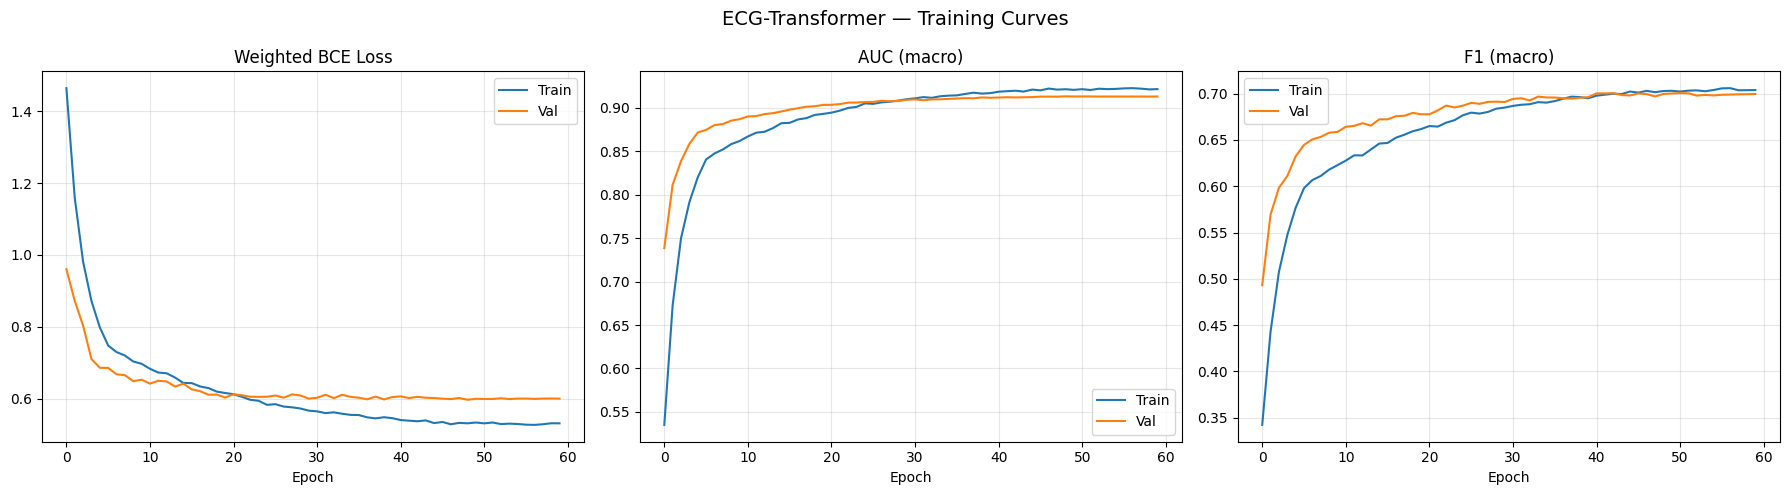

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(history.history["loss"], label="Train"); axes[0].plot(history.history["val_loss"], label="Val")
axes[0].set_title("Weighted BCE Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(history.history["auc"], label="Train"); axes[1].plot(history.history["val_auc"], label="Val")
axes[1].set_title("AUC (macro)"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
axes[2].plot(history.history["f1"], label="Train"); axes[2].plot(history.history["val_f1"], label="Val")
axes[2].set_title("F1 (macro)"); axes[2].set_xlabel("Epoch"); axes[2].legend(); axes[2].grid(True, alpha=0.3)
plt.suptitle("ECG-Transformer — Training Curves", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(model_save_dir, "training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Load best model — compile=False avoids deserializing the WarmupCosineDecay schedule
best_model = keras.models.load_model(best_model_path, custom_objects={
    "ECGAugmentation": ECGAugmentation,
    "PatchEmbedding": PatchEmbedding, "CLSToken": CLSToken,
    "LearnablePositionalEncoding": LearnablePositionalEncoding,
    "TransformerEncoderBlock": TransformerEncoderBlock,
}, compile=False)

Y_pred_prob = best_model.predict([X_test, F_test], batch_size=64, verbose=1)
Y_pred = (Y_pred_prob >= 0.5).astype(int)

print("=" * 60)
print("PER-CLASS METRICS — ECG-Transformer (Test Set — Fold 10)")
print("=" * 60)

auc_scores = {}
for i, sc in enumerate(SUPERCLASSES):
    try:
        auc = roc_auc_score(Y_test[:, i], Y_pred_prob[:, i])
    except ValueError:
        auc = float("nan")
    auc_scores[sc] = auc
    print(f"  {sc:>5}: AUC = {auc:.4f}")

macro_auc = np.nanmean(list(auc_scores.values()))
print(f"\n  Macro AUC: {macro_auc:.4f}")
print("\n" + "=" * 60)
print(classification_report(Y_test, Y_pred, target_names=SUPERCLASSES, zero_division=0))

f1_per_class = f1_score(Y_test, Y_pred, average=None, zero_division=0)
f1_macro = f1_score(Y_test, Y_pred, average="macro", zero_division=0)
print(f"Per-class F1: {dict(zip(SUPERCLASSES, [f'{f:.4f}' for f in f1_per_class]))}")
print(f"Macro F1:     {f1_macro:.4f}")

35/35 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step
PER-CLASS METRICS — ECG-Transformer (Test Set — Fold 10)
   NORM: AUC = 0.9344
     MI: AUC = 0.8743
   STTC: AUC = 0.9265
     CD: AUC = 0.8914
    HYP: AUC = 0.8823

  Macro AUC: 0.9018

              precision    recall  f1-score   support

        NORM       0.73      0.96      0.83       963
          MI       0.60      0.76      0.67       550
        STTC       0.64      0.86      0.73       506
          CD       0.64      0.75      0.69       496
         HYP       0.38      0.76      0.51       262

   micro avg       0.63      0.85      0.72      2777
   macro avg       0.60      0.82      0.69      2777
weighted avg       0.64      0.85      0.73      2777
 samples avg       0.69      0.83      0.73      2777

Per-class F1: {'NORM': '0.8309', 'MI': '0.6699', 'STTC': '0.7336', 'CD': '0.6900', 'HYP': '0.5051'}
Macro F1:     0.6859


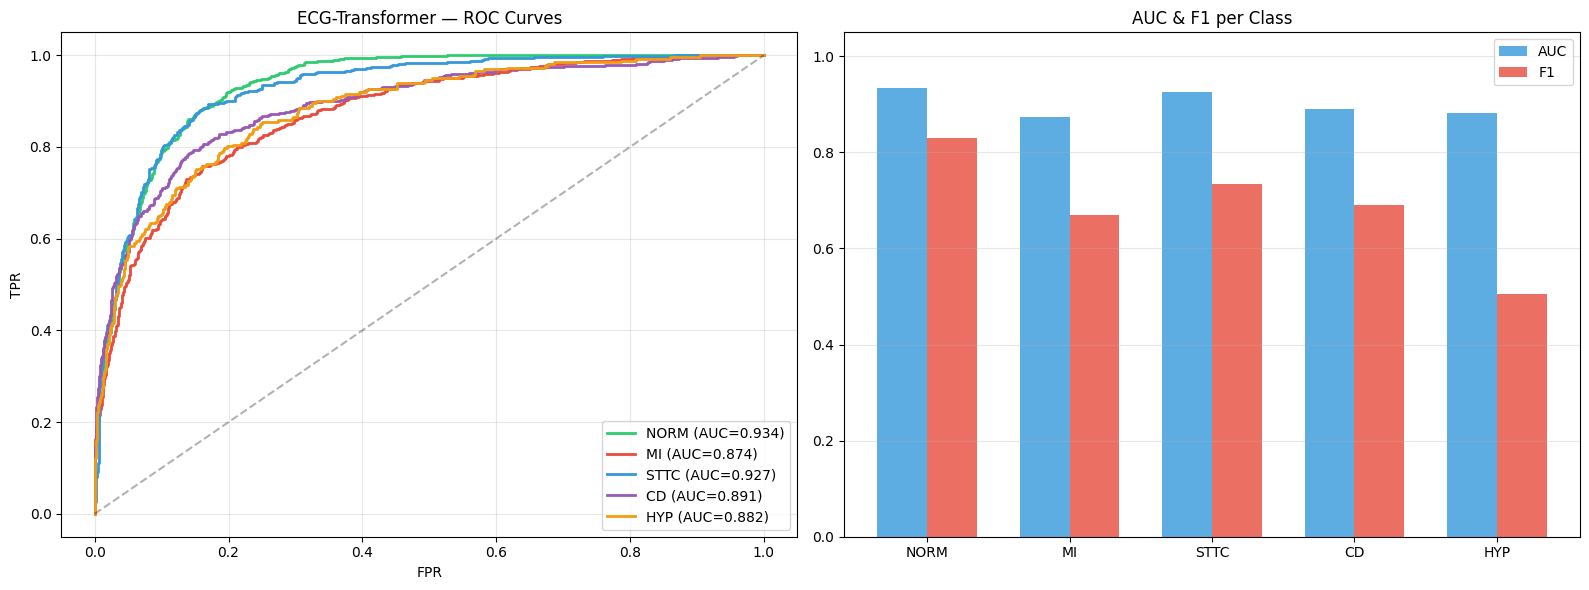

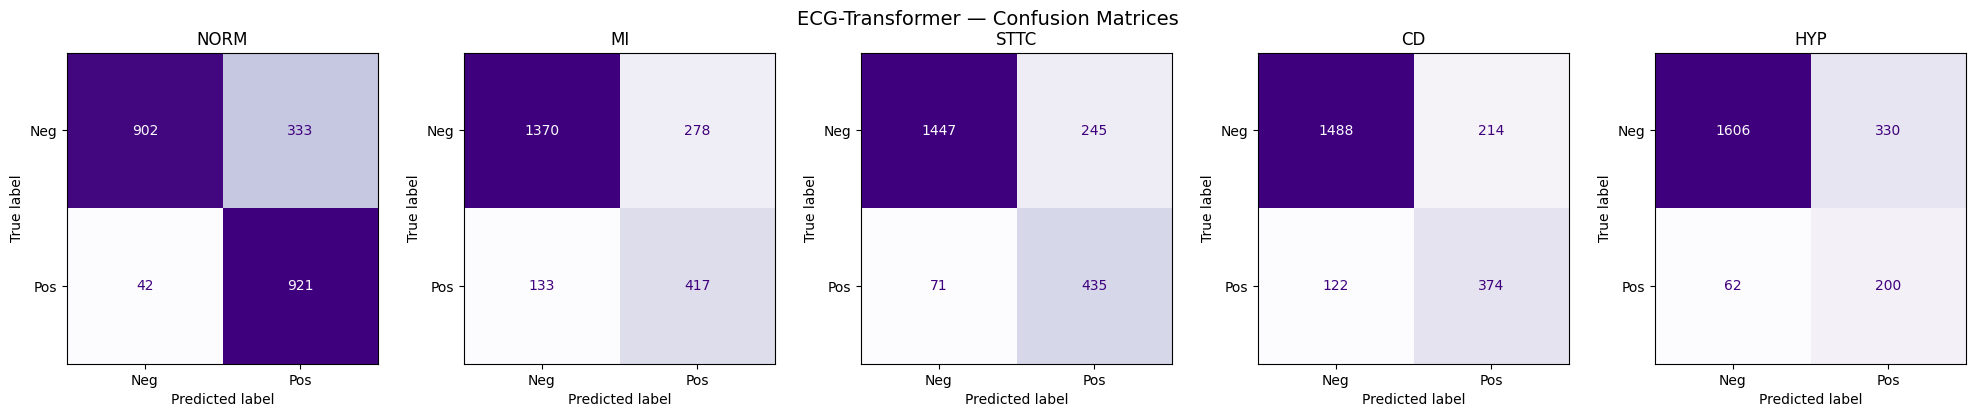

In [11]:
# ── Plots ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = ["#2ecc71", "#e74c3c", "#3498db", "#9b59b6", "#f39c12"]
for i, (sc, color) in enumerate(zip(SUPERCLASSES, colors)):
    fpr, tpr, _ = roc_curve(Y_test[:, i], Y_pred_prob[:, i])
    axes[0].plot(fpr, tpr, label=f"{sc} (AUC={auc_scores[sc]:.3f})", color=color, linewidth=2)
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.3)
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[0].set_title("ECG-Transformer — ROC Curves"); axes[0].legend(loc="lower right"); axes[0].grid(True, alpha=0.3)

x_pos = np.arange(len(SUPERCLASSES)); width = 0.35
axes[1].bar(x_pos - width/2, [auc_scores[sc] for sc in SUPERCLASSES], width, label="AUC", color="#3498db", alpha=0.8)
axes[1].bar(x_pos + width/2, f1_per_class, width, label="F1", color="#e74c3c", alpha=0.8)
axes[1].set_xticks(x_pos); axes[1].set_xticklabels(SUPERCLASSES); axes[1].set_ylim(0, 1.05)
axes[1].set_title("AUC & F1 per Class"); axes[1].legend(); axes[1].grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(os.path.join(model_save_dir, "roc_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, (ax, sc) in enumerate(zip(axes, SUPERCLASSES)):
    cm = confusion_matrix(Y_test[:, i], Y_pred[:, i])
    ConfusionMatrixDisplay(cm, display_labels=["Neg", "Pos"]).plot(ax=ax, colorbar=False, cmap="Purples")
    ax.set_title(sc)
plt.suptitle("ECG-Transformer — Confusion Matrices", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(model_save_dir, "confusion_matrices.png"), dpi=150, bbox_inches="tight")
plt.show()

## 5. TFLite Conversion

In [12]:
converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tflite_model = converter.convert()

tflite_path = os.path.join(model_save_dir, "transformer_fp16.tflite")
with open(tflite_path, "wb") as f:
    f.write(tflite_model)

keras_size = os.path.getsize(best_model_path) / 1e6
tflite_size = os.path.getsize(tflite_path) / 1e6
print(f"Keras:  {keras_size:.2f} MB → TFLite: {tflite_size:.2f} MB ({tflite_size/keras_size*100:.1f}%)")

# Validate
def run_tflite_inference(path, X_sig, X_feat):
    interp = tf.lite.Interpreter(model_path=path)
    interp.allocate_tensors()
    inp, out = interp.get_input_details(), interp.get_output_details()
    preds = []
    for i in range(len(X_sig)):
        for d in inp:
            if "signal" in d["name"]: interp.set_tensor(d["index"], X_sig[i:i+1].astype(np.float32))
            elif "feature" in d["name"]: interp.set_tensor(d["index"], X_feat[i:i+1].astype(np.float32))
        interp.invoke()
        preds.append(interp.get_tensor(out[0]["index"])[0])
    return np.array(preds)

n_eval = min(500, len(X_test))
tflite_preds = run_tflite_inference(tflite_path, X_test[:n_eval], F_test[:n_eval])
tflite_auc = roc_auc_score(Y_test[:n_eval], tflite_preds, average="macro")
tflite_f1 = f1_score(Y_test[:n_eval], (tflite_preds >= 0.5).astype(int), average="macro", zero_division=0)
print(f"TFLite AUC: {tflite_auc:.4f} | Keras: {macro_auc:.4f}")
print(f"TFLite F1:  {tflite_f1:.4f} | Keras: {f1_macro:.4f}")

Saved artifact at '/tmp/tmp9cj6ywr_'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 1000, 12), dtype=tf.float32, name='signal_input'), TensorSpec(shape=(None, 531), dtype=tf.float32, name='feature_input')]
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  139735744194960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139735744198416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139735744198608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139735744196880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139735744188432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139735744188624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139735744194576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139735744198224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139735744193616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1397357441